# 02 – Functional neighbourhoods from the trip graph

**Question:** which parts of NYC behave as self-contained bike-share areas, and does the answer change over the day and week?

Pipeline outputs used: `edges.parquet` (directed station→station trip counts per time slice), `stations.parquet`, `station_areas.parquet` (official NTAs/boroughs, from `python -m citibike.geo`).

Methods:
* **Modularity** and **spectral clustering** (course topic: graph clustering), implemented in `citibike.graph`.
* **Louvain** (igraph), the standard modularity optimiser.
* **Infomap / the map equation** (*not taught in the course*). Instead of comparing edge density with a random-graph null model like modularity does, Infomap follows a random walker along the *directed*, trip-weighted edges. It looks for the partition that gives the shortest description of the walker's path (a two-level code: one codebook for movement between modules, one per module for movement inside it). A module is therefore an area that a "random rider" tends not to leave, which is exactly our notion of a self-contained area. Infomap also uses trip direction, which Louvain and spectral clustering discard.

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score as ari
from sklearn.metrics import normalized_mutual_info_score as nmi

from citibike import graph as G
from citibike.paths import FIGURES, PROCESSED

FIGURES.mkdir(exist_ok=True)
from citibike.plots import CATEGORICAL, NEUTRAL, TEXT_MUTED, community_map, relabel_by_size

pd.set_option("display.width", 200)

## 1. The graph

* **Nodes:** stations that average at least 1 trip per day over the days they were active (stations below that are too sparse to place reliably). The same node set is used for every time slice so that partitions can be compared.
* **Edges:** directed trip counts $W_{ij}$, with round trips (self-loops) removed. Louvain, spectral clustering and modularity need an undirected graph, so they use $A = W + W^\top$, the trips between two stations in either direction. Infomap uses $W$ directly.
* Only the largest connected component is kept. In practice that's every node.

In [2]:
g = G.load_graph("all")
A = g.A
st = pd.read_parquet(PROCESSED / "stations.parquet").set_index("station_id").loc[g.ids]
areas = pd.read_parquet(PROCESSED / "station_areas.parquet").set_index("station_id").loc[g.ids]
n_all = len(pd.read_parquet(PROCESSED / "stations.parquet"))
print(f"{len(g.ids)} of {n_all} stations, {g.W.nnz:,} directed edges, {g.W.sum():,.0f} trips, "
      f"density {g.W.nnz / len(g.ids) ** 2:.2f}")
w = g.W.data
print("edge weight quantiles (trips/year):", np.quantile(w, [0.5, 0.9, 0.99, 0.999]).round(0), " max", w.max())

2384 of 2384 stations, 1,612,910 directed edges, 44,567,641 trips, density 0.28
edge weight quantiles (trips/year): [   4.   60.  397. 1132.]  max 9744.0


The graph is dense (28% of all station pairs are connected) but the weights are very skewed. Most pairs see a handful of trips a year, and a few see thousands. Methods that use the weights, as all of ours do, are therefore driven by the strong local links rather than the many weak long ones.

## 2. Checking our implementations

**Modularity.** For a partition into communities $c$, $Q = \sum_c \left[\frac{L_c}{2m} - \gamma\left(\frac{d_c}{2m}\right)^2\right]$. Here $L_c$ is the total edge weight inside $c$ (counting both directions), $d_c$ the total strength of its nodes, $2m=\sum_{ij}A_{ij}$, and $\gamma$ the resolution. We compute it with a sparse one-hot matrix $H$: the diagonal of $H^\top A H$ gives $L_c$, and $H^\top d$ gives $d_c$. It agrees with igraph to machine precision:

In [3]:
import igraph as ig

lab = G.louvain(A, 1.0, seed=0)
up = sp.triu(A, k=1).tocoo()
gi = ig.Graph(n=A.shape[0], edges=np.column_stack([up.row, up.col]).tolist())
for gamma in (0.5, 1.0, 2.0):
    ours, ref = G.modularity(A, lab, gamma), gi.modularity(lab, weights=up.data, resolution=gamma)
    print(f"gamma={gamma}: ours {ours:.12f}  igraph {ref:.12f}")
    assert abs(ours - ref) < 1e-9

gamma=0.5: ours 0.634638265646  igraph 0.634638265646
gamma=1.0: ours 0.522184667040  igraph 0.522184667040


gamma=2.0: ours 0.297277469828  igraph 0.297277469828


**Spectral clustering** (Ng, Jordan & Weiss): take the top-$k$ eigenvectors of $D^{-1/2} A D^{-1/2}$, normalise each row to unit length, and run k-means on the rows. Sanity check on a planted-partition graph: 4 blocks of 100 nodes, edge probability 0.10 inside a block and 0.02 between blocks. Each node then expects about 10 links inside its block and 6 outside, so a few nodes end up genuinely ambiguous, and an ARI somewhat below 1 is expected:

In [4]:
rng = np.random.default_rng(0)
truth = np.repeat(np.arange(4), 100)
P = np.where(truth[:, None] == truth[None, :], 0.10, 0.02)
upper = np.triu(rng.random(P.shape) < P, k=1)
S = sp.csr_matrix((upper | upper.T).astype(float))
print("ARI vs planted blocks:", ari(truth, G.spectral_clustering(S, 4)))

ARI vs planted blocks: 0.9407645676110356


## 3. Choosing the number of communities

**Spectral: eigengap.** If the graph has $k$ well-separated communities, $D^{-1/2}AD^{-1/2}$ has $k$ eigenvalues close to 1, followed by a gap.

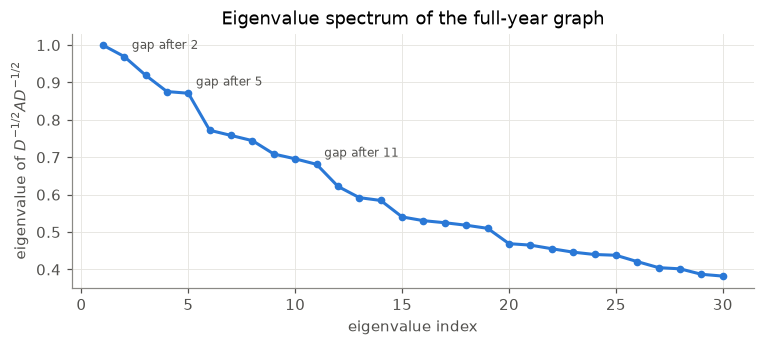

In [5]:
vals, _ = G.spectral_embedding(A, 30)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(1, 31), vals, "o-", color=CATEGORICAL[0], markersize=4)
gaps = -np.diff(vals)
for i in np.argsort(gaps)[::-1][:3]:
    ax.annotate(f"gap after {i + 1}", (i + 1, vals[i]), xytext=(5, 5), textcoords="offset points", fontsize=8, color=TEXT_MUTED)
ax.set(xlabel="eigenvalue index", ylabel="eigenvalue of $D^{-1/2}AD^{-1/2}$", title="Eigenvalue spectrum of the full-year graph");

There is no single dominant gap. The largest gaps come after 5, 11 and 2 eigenvalues, and otherwise the spectrum decays smoothly. The gap after 2 comes from Governors Island, which is almost disconnected from the rest. This is the first sign that the city doesn't fall into a few sharply separated blocks. Instead, community structure exists at several scales.

**Retention vs. k, with a geographic baseline.** Modularity alone can't tell us whether a partition says more than "nearby stations belong together". So for every method we compute **flow retention**, the share of all trips that start and end in the same community, as a function of the number of communities $k$. We compare it with a baseline that only knows geography: **k-means on station coordinates** with the same $k$. We also add the official areas (boroughs, 45 community districts, 130 NTAs). For Louvain we vary the resolution $\gamma$, for spectral clustering $k$, and for Infomap the *Markov time* (how far the random walker moves between observations: shorter times give more, smaller modules).

In [6]:
xy = np.c_[st.lat, st.lng * np.cos(np.radians(40.7))]
rows = []
def record(method, labels, param):
    rows.append(dict(method=method, param=param, k=len(np.unique(labels)), Q=G.modularity(A, labels),
                     retention=G.flow_retention(g.W, labels), largest_share=np.bincount(pd.factorize(labels)[0]).max() / len(labels)))

t = time.time()
for gamma in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6]:
    record("Louvain", G.louvain(A, gamma, seed=0), gamma)
for k in [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, 40]:
    record("Spectral", G.spectral_clustering(A, k), k)
    record("Geographic k-means", KMeans(k, n_init=10, random_state=0).fit_predict(xy), k)
for mt in [0.75, 0.8, 0.85, 0.9, 0.95, 1, 1.05, 1.1, 1.2, 1.3, 1.4]:
    record("Infomap", G.infomap(g.W, seed=0, trials=5, markov_time=mt), mt)
for name in ["borough", "cdta", "nta"]:
    record(name, pd.factorize(areas[name])[0], None)
sweep = pd.DataFrame(rows)
print(f"{time.time() - t:.0f} s")
# "trivial" = one community holds > 90% of stations (e.g. only Governors Island split off)
sweep["trivial"] = sweep.largest_share > 0.9
sweep.query("method != 'Geographic k-means'").round(3)

236 s


,method,param,k,Q,retention,largest_share,trivial
0,Louvain,0.25,3,0.391,0.934,0.556,False
1,Louvain,0.50,5,0.443,0.914,0.377,False
2,Louvain,0.75,6,0.523,0.798,0.377,False
3,Louvain,1.00,7,0.522,0.747,0.260,False
4,Louvain,1.50,7,0.515,0.706,0.279,False
5,Louvain,2.00,13,0.456,0.558,0.232,False
6,Louvain,3.00,19,0.408,0.474,0.182,False
7,Louvain,4.00,39,0.357,0.402,0.169,False
8,Louvain,6.00,109,0.267,0.290,0.165,False
9,Spectral,2.00,2,0.001,1.000,0.999,True


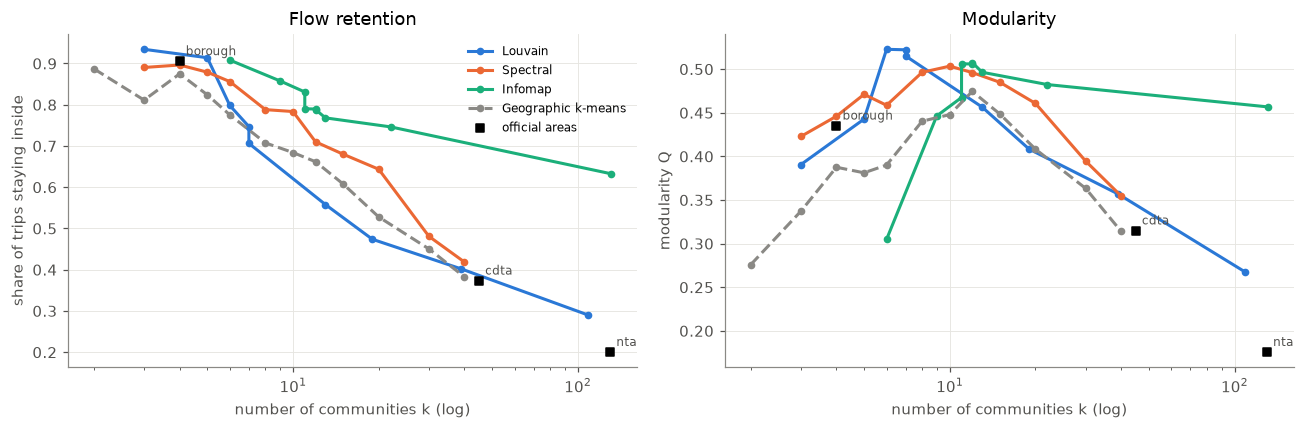

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3))
series = ["Louvain", "Spectral", "Infomap", "Geographic k-means"]
colors = dict(zip(series, [CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[2], NEUTRAL]))
for m in series:
    d = sweep[(sweep.method == m) & ~sweep.trivial & (sweep.k <= 150)].sort_values("k")
    for ax, col in zip(axs, ["retention", "Q"]):
        ax.plot(d.k, d[col], marker="o", ls="--" if m == "Geographic k-means" else "-",
                color=colors[m], markersize=4, label=m)
admin = sweep[sweep.method.isin(["borough", "cdta", "nta"])]
for ax, col in zip(axs, ["retention", "Q"]):
    ax.scatter(admin.k, admin[col], marker="s", color="black", s=25, zorder=3, label="official areas")
    for _, r in admin.iterrows():
        ax.annotate(r.method, (r.k, r[col]), xytext=(4, 4), textcoords="offset points", fontsize=7, color=TEXT_MUTED)
    ax.set_xscale("log"); ax.set_xlabel("number of communities k (log)")
axs[0].set(ylabel="share of trips staying inside", title="Flow retention")
axs[1].set(ylabel="modularity Q", title="Modularity")
axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "retention_modularity.pdf", bbox_inches="tight")

How to read this:
* Retention always falls as $k$ grows, because smaller areas keep fewer trips inside. So methods can only be compared **at the same $k$**. The dashed gray line shows what geography alone achieves.
* **Spectral clustering is above the geographic baseline at every $k$ from 3 to 40** (k=10: 78% vs 68%), and **Infomap at every $k$ it reaches** (12 modules: 79% vs 66%; 22 modules: 75% vs 53% for geography at 20; 131 modules: 63% vs 20% for the 130 NTAs). So the communities capture structure that distance alone does not.
* **Louvain only beats geography at low resolution** ($\gamma \le 0.75$, $k \le 6$). At $\gamma=1$ it is level with geography, and at $\gamma = 2$–3 it falls *below* it (13 communities: 56% vs 66%). Modularity with a large $\gamma$ penalises large communities, so it cuts up the dense Manhattan core, where trips run in every direction. The result is small areas that riders constantly leave. This is a reason not to judge partitions by $Q$ alone.
* A caveat in Infomap's favour: retention is close to what Infomap optimises (flow that stays inside modules), and spectral clustering optimises a related quantity, the normalised cut. On modularity, Louvain's own objective, Louvain is best (Q = 0.52 at k = 6–7), ahead of Infomap (0.51 at k = 12) and spectral (0.50 at k = 10). All three are far above geography (best Q = 0.47) and the official areas.
* **Boroughs are a very good 4-way split** (90.5% retention, better than spectral clustering with k=4 at 89.6%), because the rivers separate them. **The finer official areas are not**: community districts score about the same as geography, and NTAs keep only 20% of trips inside.

## 4. The chosen partitions

We continue with three partitions near the modularity peak: **Louvain** ($\gamma=1$), **spectral clustering** ($k=10$, one of the eigengap candidates) and **Infomap** (default Markov time 1). Communities are numbered by size (stations), and colours only separate neighbouring areas.

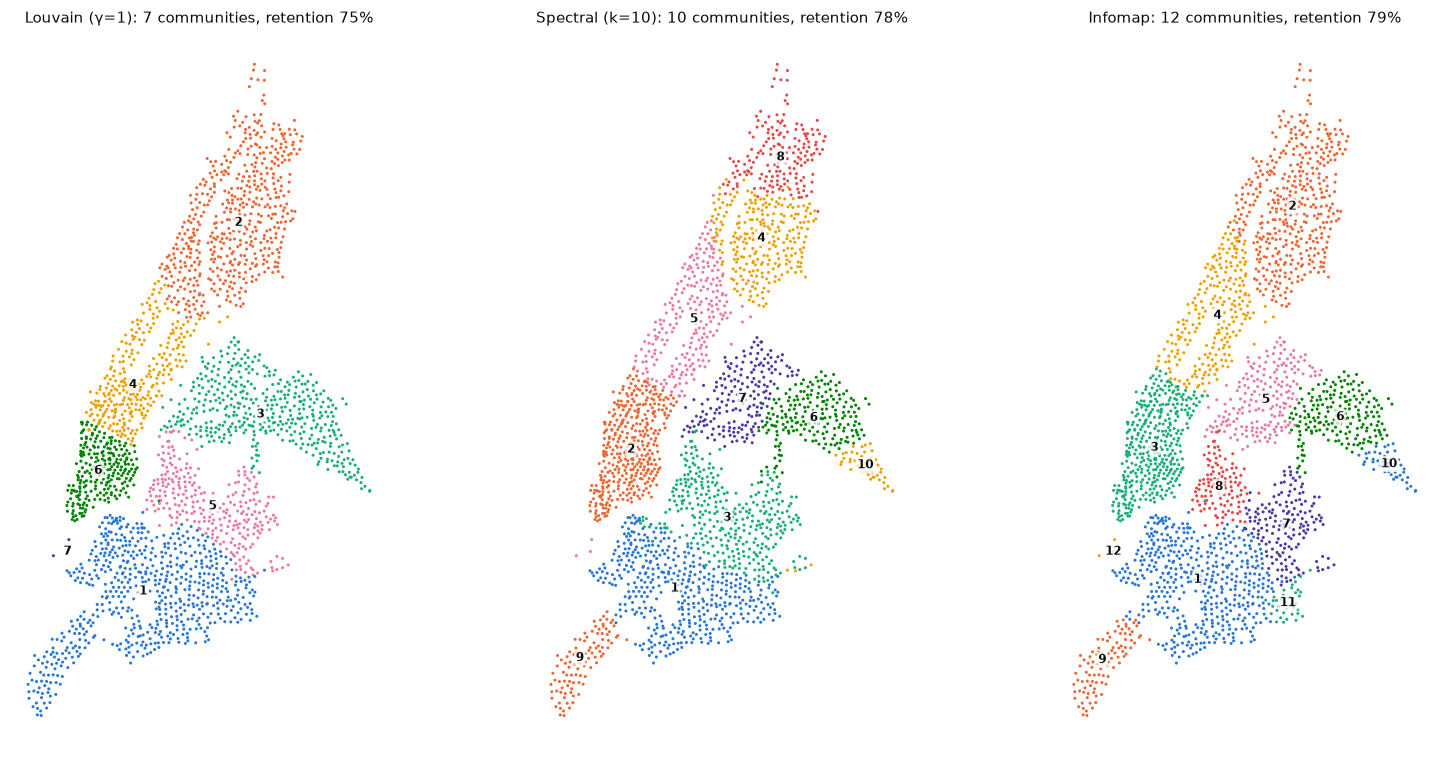

In [8]:
parts = {
    "Louvain (γ=1)": relabel_by_size(G.louvain(A, 1.0, seed=0)),
    "Spectral (k=10)": relabel_by_size(G.spectral_clustering(A, 10)),
    "Infomap": relabel_by_size(G.infomap(g.W, seed=0)),
}
fig, axs = plt.subplots(1, 3, figsize=(15, 7))
for ax, (name, l) in zip(axs, parts.items()):
    community_map(ax, st, l, f"{name}: {len(np.unique(l))} communities, retention {G.flow_retention(g.W, l):.0%}")
fig.tight_layout(); fig.savefig(FIGURES / "partitions.pdf", bbox_inches="tight")

In [9]:
im = parts["Infomap"]
tab = G.community_table(g, im)
df = areas.assign(c=im)
tab["main areas (most stations)"] = tab.community.map(df.groupby("c").nta_name.agg(lambda s: ", ".join(s.value_counts().index[:3])))
tab["boroughs"] = tab.community.map(df.groupby("c").borough.agg(lambda s: ", ".join(f"{b} {n}" for b, n in s.value_counts().items())))
tab.round(3)

,community,stations,trips_out,self_contained,main areas (most stations),boroughs
0,3,394,21007040.0,0.861,"Chelsea-Hudson Yards, East Village, Midtown-Ti...","Manhattan 393, Brooklyn 1"
1,1,476,7695622.0,0.807,"Carroll Gardens-Cobble Hill-Gowanus-Red Hook, ...",Brooklyn 476
2,4,235,6386628.0,0.691,"East Harlem (North), Harlem (North), Upper Wes...",Manhattan 235
3,8,114,3638658.0,0.624,"Williamsburg, East Williamsburg, Greenpoint","Brooklyn 112, Queens 2"
4,5,196,2103922.0,0.743,"Astoria (North)-Ditmars-Steinway, Sunnyside, A...","Queens 193, Manhattan 3"
5,2,427,1506728.0,0.842,"Mott Haven-Port Morris, Concourse-Concourse Vi...","Bronx 365, Manhattan 62"
6,7,168,1317286.0,0.550,"Ridgewood, Bushwick (East), Bushwick (West)","Brooklyn 99, Queens 69"
7,6,192,638788.0,0.740,"Jackson Heights, Elmhurst, Woodside",Queens 192
8,9,97,228614.0,0.649,"Bay Ridge, Sunset Park (West), Sunset Park (Ce...",Brooklyn 97
9,10,46,29194.0,0.720,"Forest Hills, Rego Park, Flushing Meadows-Coro...",Queens 46


**Infomap's areas** (numbers as on the map and in the table):
* **3: Manhattan below 59th St** is the busiest area in the system: 21M trips a year start there, and 86% of them stay inside.
* **4: the Upper West/East Side + Harlem** form their own area north of 59th St, and **2: the Bronx + northern Manhattan** (Inwood, upper Washington Heights) another. That area **crosses the Harlem River borough border**: 62 Manhattan stations ride with the Bronx.
* **7: Bushwick (Brooklyn) + Ridgewood (Queens)** form one area that **crosses the Brooklyn–Queens border** (99 + 69 stations). Williamsburg/Greenpoint (8) is its own area next to it.
* **5: Astoria/Long Island City/Sunnyside** includes **Roosevelt Island** (officially Manhattan, 3 stations), which is connected to Queens by bridge.
* **12: Governors Island** (3 stations, reachable only by ferry) is its own area, with 98% of trips staying on the island. A useful sanity check.
* **11: Brownsville/East Flatbush** is a weak area: only 32% of its few trips (2.6k a year) stay inside. It sits at the edge of the network and is the least stable result.

Louvain and spectral clustering find the same cross-border areas but cut Manhattan differently. Louvain, for example, splits it at about 30th St into downtown and midtown/uptown, and puts Harlem with the Bronx.

## 5. Agreement with official areas

In [10]:
rows = []
for name, l in parts.items():
    for level in ["borough", "cdta", "nta"]:
        rows.append(dict(partition=name, level=level, ARI=ari(areas[level], l), NMI=nmi(areas[level], l)))
pd.DataFrame(rows).pivot(index="partition", columns="level", values=["NMI", "ARI"]).round(3)

NMI                   ARI              
level           borough   cdta    nta borough   cdta    nta
partition                                                  
Infomap           0.686  0.690  0.614   0.513  0.280  0.125
Louvain (γ=1)     0.731  0.602  0.525   0.613  0.204  0.086
Spectral (k=10)   0.673  0.673  0.604   0.482  0.283  0.131

In [11]:
pd.crosstab(pd.Series(im, index=g.ids, name="Infomap community"), areas.borough)

borough,Bronx,Brooklyn,Manhattan,Queens
Infomap community,,,,
1,0,476,0,0
2,365,0,62,0
3,0,1,393,0
4,0,0,235,0
5,0,0,3,193
6,0,0,0,192
7,0,99,0,69
8,0,112,0,2
9,0,97,0,0


NMI with boroughs is about 0.7. The communities are mostly *nested inside* boroughs, apart from the cross-border areas above, and they are much coarser than NTAs (ARI ≈ 0.1 with NTAs, since one community holds dozens of NTAs). Boroughs are a sensible first approximation, but they miss the three cross-border areas, which are exactly where cycling links places that the administrative map separates.

## 6. Robustness to randomness

Louvain, Infomap and k-means (inside spectral clustering) all depend on a random seed. Before comparing time slices, we measure how much partitions change *just from the seed*. Differences between time slices only mean something if they are larger than this.

In [12]:
stab = {}
for name, f in [("Louvain (γ=1)", lambda s: G.louvain(A, 1.0, s)),
                ("Spectral (k=10)", lambda s: G.spectral_clustering(A, 10, s)),
                ("Infomap", lambda s: G.infomap(g.W, s, trials=5))]:
    ls = [f(s) for s in range(10)]
    pair = [ari(a, b) for a, b in itertools.combinations(ls, 2)]
    stab[name] = dict(mean_ARI=np.mean(pair), min_ARI=np.min(pair), k_values=sorted({len(np.unique(l)) for l in ls}))
pd.DataFrame(stab).T

,mean_ARI,min_ARI,k_values
Louvain (γ=1),0.881718,0.788725,"[7, 8]"
Spectral (k=10),0.998453,0.995687,[10]
Infomap,0.987335,0.969395,[12]


Spectral clustering is almost deterministic (ARI 0.998), and Infomap is very stable (ARI ≈ 0.99, always 12 modules). **Louvain is noticeably less stable**: $k$ varies between 7 and 8 and the mean ARI between seeds is ≈0.88. That's the well-known degeneracy of the modularity landscape, where many quite different partitions have almost the same $Q$. For the time-slice comparison we therefore use Infomap, and compare each slice's change against Infomap's own seed noise in that slice (column `seed_ARI`).

## 7. How the areas change over the day and week

One graph per time slice (start time of the trip; holidays count as weekend):

In [13]:
slices = ["weekday_am", "weekday_midday", "weekday_pm", "weekday_night", "weekend"]
full = pd.Series(G.infomap(g.W, seed=0), index=g.ids)
full_ref = pd.Series(parts["Infomap"], index=g.ids)
slice_labels, rows = {}, []
for s in slices:
    h = G.load_graph(s, ids=g.ids)
    runs = [G.infomap(h.W, seed=i, trials=5) for i in range(3)]
    l = runs[0]
    b = full.loc[h.ids].to_numpy()
    rows.append(dict(slice=s, trips=h.W.sum(), k=len(np.unique(l)),
                     retention_own=G.flow_retention(h.W, l), retention_full_year_partition=G.flow_retention(h.W, b),
                     ARI_vs_full_year=ari(b, l), seed_ARI=np.mean([ari(x, y) for x, y in itertools.combinations(runs, 2)])))
    slice_labels[s] = pd.Series(G.align_labels(full_ref.loc[h.ids].to_numpy(), l), index=h.ids)
slices_df = pd.DataFrame(rows)
slices_df.round(3)

,slice,trips,k,retention_own,retention_full_year_partition,ARI_vs_full_year,seed_ARI
0,weekday_am,6782275.0,12,0.844,0.794,0.873,0.990
1,weekday_midday,9137854.0,13,0.791,0.813,0.903,0.958
2,weekday_pm,10762516.0,12,0.789,0.791,0.973,1.000
3,weekday_night,5448355.0,13,0.782,0.783,0.930,0.896
4,weekend,12436641.0,12,0.771,0.772,0.980,0.969


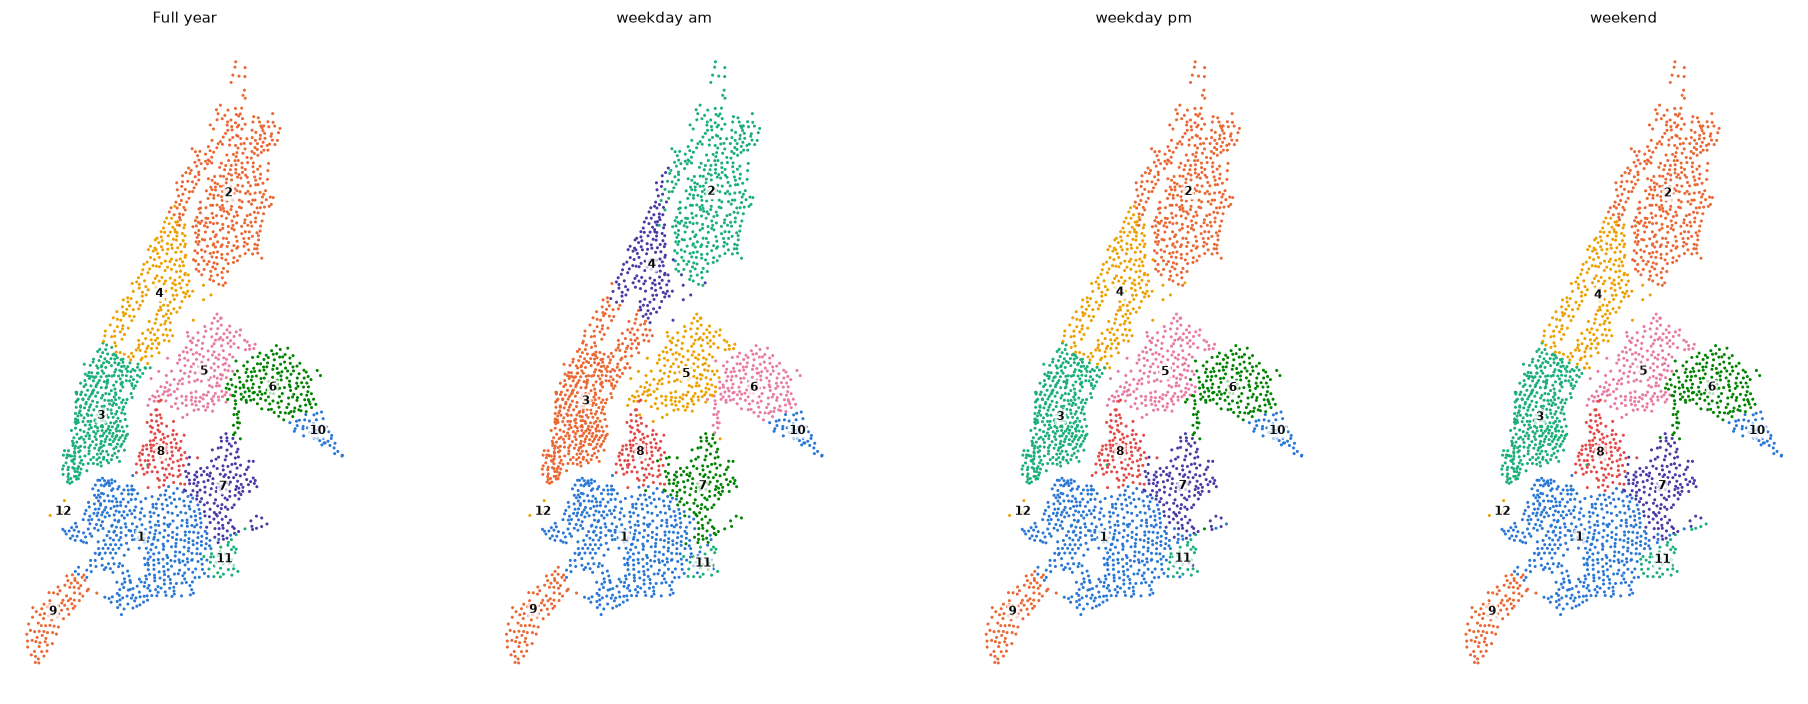

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(8, 3.6))
community_map(axs[0], st, full_ref.to_numpy(), "Full year", s=0.8, fontsize=5.5)
for ax, s in zip(axs[1:], ["weekday_am", "weekday_pm", "weekend"]):
    l = slice_labels[s]
    community_map(ax, st.loc[l.index], l.to_numpy(), s.replace("_", " "), s=0.8, fontsize=5.5)
fig.tight_layout(); fig.savefig(FIGURES / "infomap_slices.pdf", bbox_inches="tight")

In [15]:
# Which stations change area in the weekday morning, and where to?
am = slice_labels["weekday_am"]
moved = pd.DataFrame({"full_year": full_ref.loc[am.index], "weekday_am": am, "nta": areas.nta_name.loc[am.index]})
moved = moved[moved.full_year != moved.weekday_am]
print(f"{len(moved)} of {len(am)} stations ({len(moved) / len(am):.0%}) are in a different area on weekday mornings")
moved.groupby(["full_year", "weekday_am"]).nta.agg(["size", lambda s: ", ".join(s.value_counts().index[:3])]).sort_values("size", ascending=False).head(10)

166 of 2380 stations (7%) are in a different area on weekday mornings


size                                         <lambda_0>
full_year weekday_am                                                         
4         3             88  Upper West Side (Central), Upper East Side-Car...
2         4             24  Washington Heights (South), Washington Heights...
6         5             12  Woodside, Astoria (East)-Woodside (North), Mou...
11        1             11          Brownsville, East Flatbush-Remsen Village
          7              8                 Brownsville, East New York (North)
7         1              7  Bedford-Stuyvesant (East), Ocean Hill, Bushwic...
1         7              4  Ocean Hill, Bedford-Stuyvesant (East), Bedford...
8         7              3                                  East Williamsburg
1         9              3                                 Sunset Park (West)
8         5              2                                         Greenpoint

A slice partition counts as *different* from the full year only if `ARI_vs_full_year` is clearly below the slice's own `seed_ARI`:
* **The weekday morning rush is the clear exception** (ARI 0.87 against a seed level of 0.99). Its own partition also keeps more of its trips inside (84%) than the full-year partition does (79%). 166 stations (7%) switch area. Most of them (88) are on the **Upper West and East Side, which join the Manhattan core**, so in the morning the core reaches up to about 104th St instead of 59th St. Washington Heights moves from the Bronx area into the Harlem area, and Woodside moves into the Astoria area. Commuting ties these neighbourhoods to the places people ride *to*.
* **Nights and weekends do not differ beyond seed noise**: weekend riding uses the same areas as the year as a whole. Midday and the PM rush differ only slightly (0.90 vs 0.96 and 0.97 vs 1.00). The evening rush is mostly morning trips in reverse, but as a *random walk* the reversed flow gives a structure much closer to the full year than the morning does.

## 8. Saving the station → area mapping

Saved for the profile analysis (notebook 03) and for phase 2. The GBFS live feed's `short_name` equals our `station_id`.

In [16]:
out = pd.DataFrame({"station_id": g.ids, "infomap": parts["Infomap"], "louvain": parts["Louvain (γ=1)"],
                    "spectral": parts["Spectral (k=10)"]})
for s, l in slice_labels.items():
    out[f"infomap_{s}"] = out.station_id.map(l).astype("Int64")
out.to_parquet(PROCESSED / "station_communities.parquet", index=False)
sweep.to_csv(PROCESSED / "community_sweep.csv", index=False)
slices_df.to_csv(PROCESSED / "community_slices.csv", index=False)
out.head()

,station_id,infomap,louvain,spectral,infomap_weekday_am,infomap_weekday_midday,infomap_weekday_pm,infomap_weekday_night,infomap_weekend
0,1964.01,9,1,9,9,9,9,9,9
1,2009.04,9,1,9,9,9,9,9,9
2,2042.01,9,1,9,9,9,9,9,9
3,2086.07,9,1,9,9,9,9,9,9
4,2118.13,9,1,9,9,9,9,9,9
